## Import Libraries

In [54]:
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("Python:", sys.executable)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("All libraries imported successfully!")

Python: c:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-02\.venv\Scripts\python.exe
OpenCV: 5.1.0
NumPy: 2.5.4
Pandas: 3.1.0
All libraries imported successfully!


## 1. Project Objectives

In [55]:
dataset_dir = Path("../data/coco8")

train_images_dir = dataset_dir / "images" / "train"
val_images_dir = dataset_dir / "images" / "val"

train_labels_dir = dataset_dir / "labels" / "train"
val_labels_dir = dataset_dir / "labels" / "val"

reports_dir = Path("../reports")
figures_dir = reports_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

print("Dataset paths configured successfully!")
print("Training images:", train_images_dir)
print("Validation images:", val_images_dir)
print("Figures directory:", figures_dir)

Dataset paths configured successfully!
Training images: ..\data\coco8\images\train
Validation images: ..\data\coco8\images\val
Figures directory: ..\reports\figures


# 2. Load Image Dataset

In [56]:
train_images = sorted(train_images_dir.glob("*.jpg"))
val_images = sorted(val_images_dir.glob("*.jpg"))

all_images = train_images + val_images

print("Training Images:", len(train_images))
print("Validation Images:", len(val_images))
print("Total Images:", len(all_images))

Training Images: 4
Validation Images: 4
Total Images: 8


## 3. Image Information Inspection

In [57]:
image_records = []

for image_path in all_images:
    with Image.open(image_path) as img:
        width, height = img.size
        image_format = img.format
        channels = len(img.getbands())
        color_mode = img.mode

    image_records.append({
        "Image": image_path.name,
        "Width": width,
        "Height": height,
        "Channels": channels,
        "Color Mode": color_mode,
        "Format": image_format,
        "Split": "Train" if image_path in train_images else "Validation",
        "File Size (KB)": round(image_path.stat().st_size / 1024, 2)
    })

image_df = pd.DataFrame(image_records)

image_df

,Image,Width,Height,Channels,Color Mode,Format,Split,File Size (KB)
0,000000000009.jpg,640,480,3,RGB,JPEG,Train,44.02
1,000000000025.jpg,640,426,3,RGB,JPEG,Train,63.45
2,000000000030.jpg,640,428,3,RGB,JPEG,Train,21.81
3,000000000034.jpg,640,425,3,RGB,JPEG,Train,70.90
4,000000000036.jpg,481,640,3,RGB,JPEG,Validation,48.11
5,000000000042.jpg,640,478,3,RGB,JPEG,Validation,41.27
6,000000000049.jpg,381,500,3,RGB,JPEG,Validation,29.59
7,000000000061.jpg,640,488,3,RGB,JPEG,Validation,97.21


## 4. Image Height Distribution

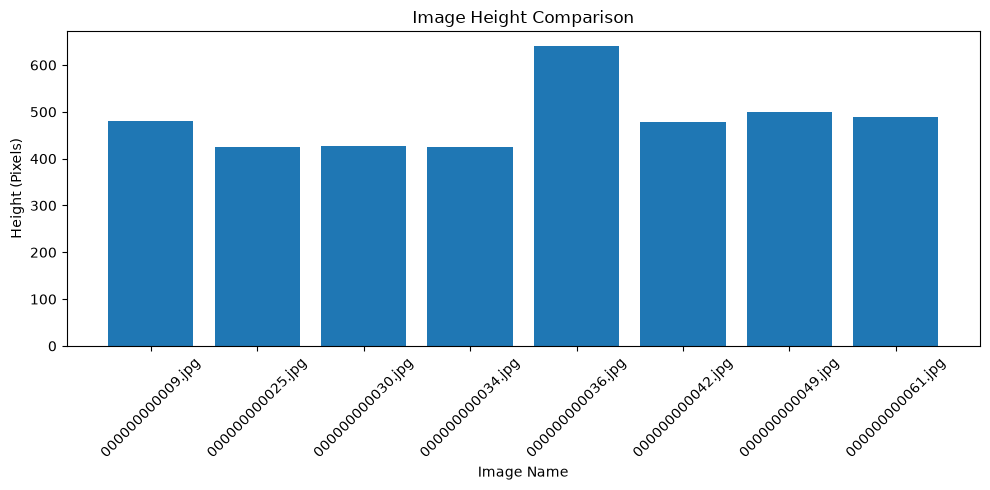

In [58]:
plt.figure(figsize=(10, 5))

plt.bar(
    image_df["Image"],
    image_df["Height"]
)

plt.title("Image Height Comparison")
plt.xlabel("Image Name")
plt.ylabel("Height (Pixels)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_dir / "image_height_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 5. Image Width Distribution

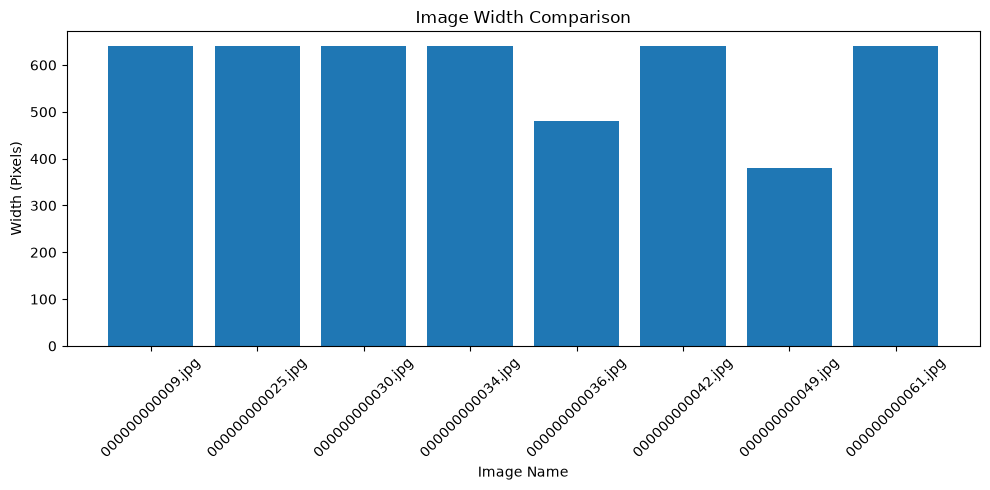

In [59]:
plt.figure(figsize=(10, 5))

plt.bar(
    image_df["Image"],
    image_df["Width"]
)

plt.title("Image Width Comparison")
plt.xlabel("Image Name")
plt.ylabel("Width (Pixels)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_dir / "image_width_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 6. Image Color Channel Analysis

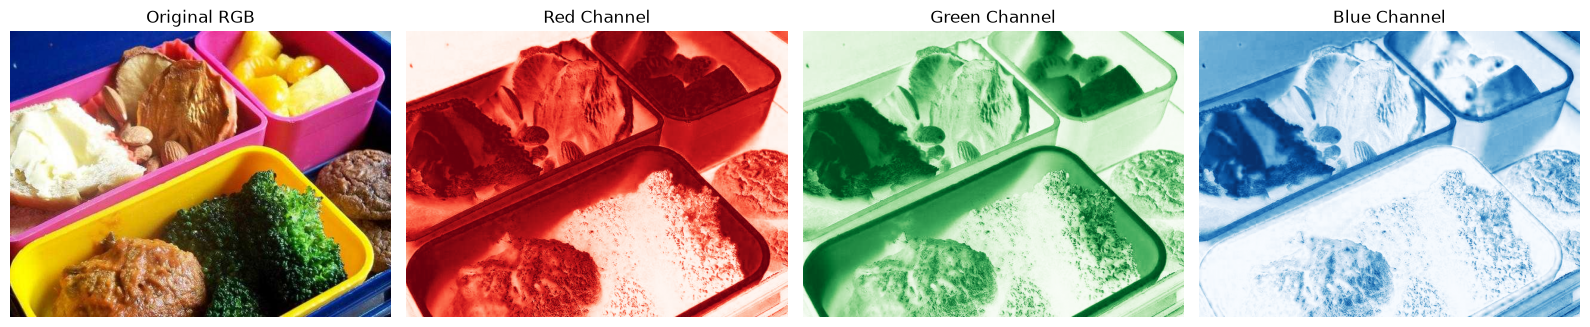

In [60]:
sample_image = cv2.imread(str(train_images[0]))

rgb_image = cv2.cvtColor(
    sample_image,
    cv2.COLOR_BGR2RGB
)

red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("Original RGB")

axes[1].imshow(red_channel, cmap="Reds")
axes[1].set_title("Red Channel")

axes[2].imshow(green_channel, cmap="Greens")
axes[2].set_title("Green Channel")

axes[3].imshow(blue_channel, cmap="Blues")
axes[3].set_title("Blue Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    figures_dir / "rgb_channel_analysis.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 7. Grayscale Image Analysis

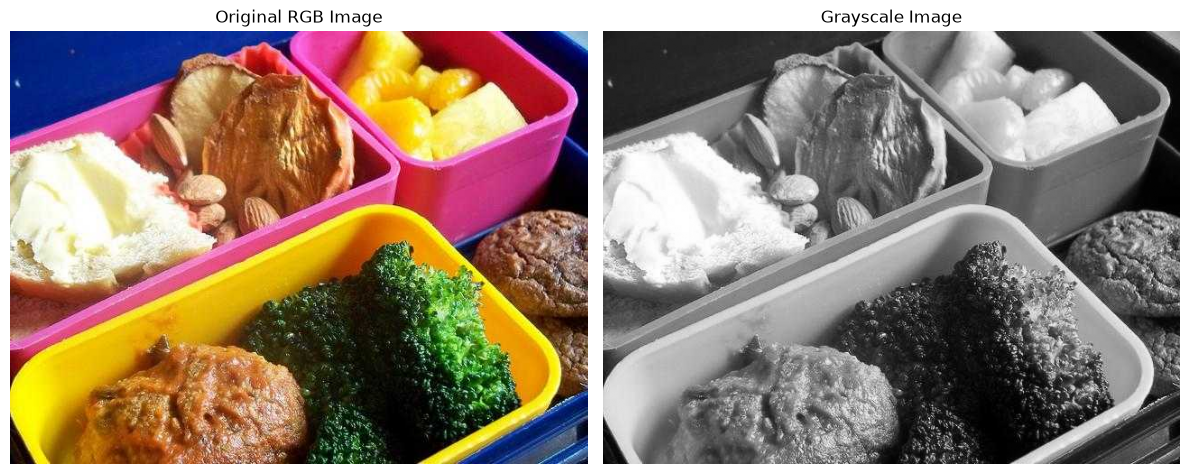

Original image shape: (480, 640, 3)
Grayscale image shape: (480, 640)


In [61]:
gray_image = cv2.cvtColor(
    sample_image,
    cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    figures_dir / "grayscale_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Original image shape:", rgb_image.shape)
print("Grayscale image shape:", gray_image.shape)

## 8. YOLO Annotation Format

In [62]:
train_label_files = sorted(train_labels_dir.glob("*.txt"))
val_label_files = sorted(val_labels_dir.glob("*.txt"))

print("Training label files:", len(train_label_files))
print("Validation label files:", len(val_label_files))

sample_label = train_label_files[0]

print("\nSample Label File:", sample_label.name)
print("\nYOLO Annotations:\n")
print(sample_label.read_text())

Training label files: 4
Validation label files: 4

Sample Label File: 000000000009.txt

YOLO Annotations:

45 0.479492 0.688771 0.955609 0.5955
45 0.736516 0.247188 0.498875 0.476417
50 0.637063 0.732938 0.494125 0.510583
45 0.339438 0.418896 0.678875 0.7815
49 0.646836 0.132552 0.118047 0.0969375
49 0.773148 0.129802 0.0907344 0.0972292
49 0.668297 0.226906 0.131281 0.146896
49 0.642859 0.0792187 0.148063 0.148062



## 9. YOLO Bounding Box Visualization

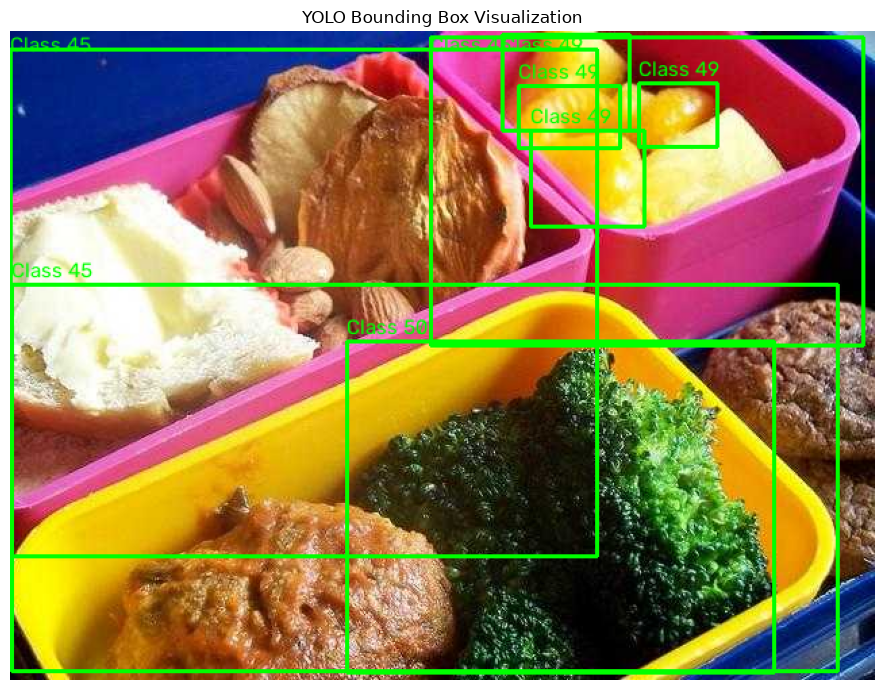

In [63]:
def draw_yolo_boxes(image_path, label_path):
    image = cv2.imread(str(image_path))

    height, width = image.shape[:2]

    labels = Path(label_path).read_text().strip().splitlines()

    for line in labels:
        values = line.split()

        class_id = int(values[0])
        x_center, y_center, box_width, box_height = map(float, values[1:])

        x_center *= width
        y_center *= height
        box_width *= width
        box_height *= height

        x1 = int(x_center - box_width / 2)
        y1 = int(y_center - box_height / 2)
        x2 = int(x_center + box_width / 2)
        y2 = int(y_center + box_height / 2)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

        cv2.putText(
            image,
            f"Class {class_id}",
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1
        )

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


annotated_image = draw_yolo_boxes(
    train_images[0],
    train_labels_dir / f"{train_images[0].stem}.txt"
)

plt.figure(figsize=(10, 7))
plt.imshow(annotated_image)
plt.title("YOLO Bounding Box Visualization")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    figures_dir / "yolo_bounding_box_visualization.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 10. Annotation Quality Validation

In [64]:
def validate_yolo_labels(image_path, label_path):
    image = cv2.imread(str(image_path))

    if image is None:
        return False, "Image could not be loaded"

    height, width = image.shape[:2]

    if not Path(label_path).exists():
        return False, "Missing label file"

    lines = Path(label_path).read_text().strip().splitlines()

    for line_number, line in enumerate(lines, start=1):
        values = line.split()

        if len(values) != 5:
            return False, f"Invalid columns at line {line_number}"

        try:
            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])
        except ValueError:
            return False, f"Invalid values at line {line_number}"

        if not 0 <= class_id <= 79:
            return False, f"Invalid class ID at line {line_number}"

        if not all(0 <= value <= 1 for value in [x, y, w, h]):
            return False, f"Coordinates out of range at line {line_number}"

        if w <= 0 or h <= 0:
            return False, f"Invalid box dimensions at line {line_number}"

        if x - w / 2 < 0 or x + w / 2 > 1:
            return False, f"Horizontal boundary error at line {line_number}"

        if y - h / 2 < 0 or y + h / 2 > 1:
            return False, f"Vertical boundary error at line {line_number}"

    return True, "Valid"

## 11. Validate Training and Validation Annotations

In [65]:
validation_records = []

for split, images, labels_dir in [
    ("Train", train_images, train_labels_dir),
    ("Validation", val_images, val_labels_dir)
]:
    for image_path in images:
        label_path = labels_dir / f"{image_path.stem}.txt"

        is_valid, message = validate_yolo_labels(
            image_path,
            label_path
        )

        object_count = (
            len(label_path.read_text().strip().splitlines())
            if label_path.exists() and label_path.read_text().strip()
            else 0
        )

        validation_records.append({
            "Image": image_path.name,
            "Split": split,
            "Valid": is_valid,
            "Object Count": object_count,
            "Status": message
        })

quality_df = pd.DataFrame(validation_records)

quality_df

,Image,Split,Valid,Object Count,Status
0,000000000009.jpg,Train,True,8,Valid
1,000000000025.jpg,Train,True,2,Valid
2,000000000030.jpg,Train,True,2,Valid
3,000000000034.jpg,Train,True,1,Valid
4,000000000036.jpg,Validation,True,2,Valid
5,000000000042.jpg,Validation,True,1,Valid
6,000000000049.jpg,Validation,True,9,Valid
7,000000000061.jpg,Validation,True,5,Valid


## 12. Annotation Quality Summary

In [66]:
total_images = len(quality_df)
valid_annotations = quality_df["Valid"].sum()
invalid_annotations = total_images - valid_annotations
total_objects = quality_df["Object Count"].sum()

print("========== ANNOTATION QUALITY SUMMARY ==========")
print("Total Images:", total_images)
print("Valid Annotations:", valid_annotations)
print("Invalid Annotations:", invalid_annotations)
print("Total Objects:", total_objects)

print("\nTraining Objects:",
      quality_df.loc[quality_df["Split"] == "Train", "Object Count"].sum())

print("Validation Objects:",
      quality_df.loc[quality_df["Split"] == "Validation", "Object Count"].sum())

========== ANNOTATION QUALITY SUMMARY ==========
Total Images: 8
Valid Annotations: 8
Invalid Annotations: 0
Total Objects: 30

Training Objects: 13
Validation Objects: 17


## 13. Generate Image Inventory Report

In [67]:
image_df.to_csv(
    reports_dir / "image_inventory.csv",
    index=False
)

print("Image inventory saved successfully!")
print("Location:", reports_dir / "image_inventory.csv")

Image inventory saved successfully!
Location: ..\reports\image_inventory.csv


## 14. Generate Annotation Quality Report

In [68]:
quality_df.to_csv(
    reports_dir / "annotation_quality.csv",
    index=False
)

print("Annotation quality report saved successfully!")
print("Location:", reports_dir / "annotation_quality.csv")

Annotation quality report saved successfully!
Location: ..\reports\annotation_quality.csv


## 15. Generate Annotation Quality Notes

In [69]:
valid_files = int(quality_df["Valid"].sum())
invalid_files = len(quality_df) - valid_files

missing_labels = sum(
    not (labels_dir / f"{image_path.stem}.txt").exists()
    for images, labels_dir in [
        (train_images, train_labels_dir),
        (val_images, val_labels_dir)
    ]
    for image_path in images
)

report_text = f"""# Day 11 - Annotation Quality Notes

## Dataset Summary
- Total images: {len(all_images)}
- Training images: {len(train_images)}
- Validation images: {len(val_images)}
- Total object annotations: {total_objects}

## Annotation Validation
- Valid image-label files: {valid_files}
- Invalid image-label files: {invalid_files}
- Missing label files: {missing_labels}
- Class IDs checked against COCO range (0-79).
- Bounding box coordinates checked for valid normalized values.
- Bounding boxes checked against image boundaries.

## Visual Inspection
- Sample YOLO bounding boxes were visualized using green rectangles.
- RGB channels and grayscale images were visualized.

## Conclusion
All {total_objects} object annotations passed the implemented structural
and coordinate validation checks.
"""

notes_path = reports_dir / "annotation_quality_notes.md"
notes_path.write_text(report_text, encoding="utf-8")

print("Annotation quality notes saved successfully!")
print("Location:", notes_path)

Annotation quality notes saved successfully!
Location: ..\reports\annotation_quality_notes.md


## 16. Final Dataset Summary

In [70]:
print("========== DAY 11 PROJECT SUMMARY ==========")

print("Total Images:", len(all_images))
print("Training Images:", len(train_images))
print("Validation Images:", len(val_images))
print("Total Objects:", total_objects)
print("Valid Label Files:", valid_files)
print("Invalid Label Files:", invalid_files)
print("Missing Label Files:", missing_labels)
print("Saved Figures:", len(list(figures_dir.glob("*.png"))))

print("\nReports Directory:", reports_dir.resolve())

========== DAY 11 PROJECT SUMMARY ==========
Total Images: 8
Training Images: 4
Validation Images: 4
Total Objects: 30
Valid Label Files: 8
Invalid Label Files: 0
Missing Label Files: 0
Saved Figures: 5

Reports Directory: C:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-11\reports
